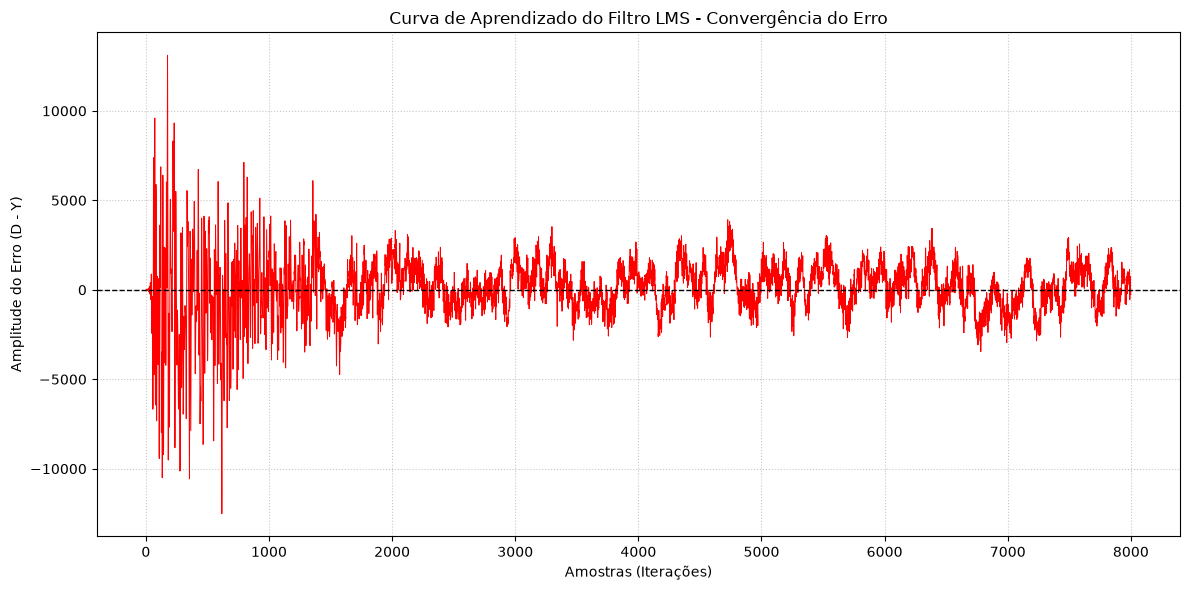

In [3]:
import matplotlib.pyplot as plt

# Caminho do arquivo gerado pelo testbench
caminho_arquivo = "/home/linse/Documentos/Codigos/vhdl/filtro_adaptativo/erro_saida.hex"
erros = []

def hex_para_sinalizado_16bits(hex_str):
    """Converte uma string hexadecimal em um inteiro com sinal de 16 bits (complemento de 2)"""
    valor = int(hex_str, 16)
    if valor >= 32768:  # 0x8000
        valor -= 65536  # 0x10000
    return valor

# Leitura e extração dos dados
with open(caminho_arquivo, 'r') as f:
    for linha in f:
        linha = linha.strip()
        if linha:
            erro_decimal = hex_para_sinalizado_16bits(linha)
            erros.append(erro_decimal)

# Configuração e plotagem do gráfico
plt.figure(figsize=(12, 6))
plt.plot(erros, color='red', linewidth=0.7)

# Linha de referência no zero
plt.axhline(y=0, color='black', linestyle='--', linewidth=1)

plt.title('Curva de Aprendizado do Filtro LMS - Convergência do Erro')
plt.xlabel('Amostras (Iterações)')
plt.ylabel('Amplitude do Erro (D - Y)')
plt.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

In [4]:
import struct

# Lê o arquivo gerado pelo VHDL em formato texto hex
with open('erro_saida.hex', 'r') as f_in, open('erro_saida.raw', 'wb') as f_out:
    for line in f_in:
        line = line.strip()
        if line:
            # Converte a string hex para inteiro com sinal de 16 bits
            val = int(line, 16)
            if val >= 32768:
                val -= 65536
            # Escreve como binário de 16 bits (2 bytes)
            f_out.write(struct.pack('<h', val))